# Unfolding examples


PyUnfold uses the `iterative_unfold` function to perform iterative unfoldings. In addition, we'll use the `Logger` callback (see the [Callbacks documentation](../callbacks.rst) for more information) to display the unfolding status at each iteration.

In [54]:
!pip install pyunfold

In [55]:
from pyunfold import iterative_unfold
from pyunfold.callbacks import Logger

In [56]:
import numpy as np
np.random.seed(2)
import matplotlib.pyplot as plt
import seaborn as sns

%matplotlib inline

In [57]:
sns.set_context(context='poster')
plt.rcParams['figure.figsize'] = (10, 8)
plt.rcParams['lines.markeredgewidth'] = 2

## True distribution

Before we can perform an unfolding, we'll need some true and observed data. We'll use the `numpy.random` module to generate some example data. Let's assume that we are measuring some observable, $X$, that is given by a normal (Gaussian) distribution.

In [58]:
num_samples = int(1e5)
true_samples = np.random.normal(loc=0.0, scale=1.0, size=num_samples)
true_samples

array([-0.41675785, -0.05626683, -2.1361961 , ...,  2.60578854,
       -0.21578792, -0.89995693])

These samples can then be binned to form a histogram of the true distribution.

In [59]:
bins = np.linspace(-3, 3, 21)
num_bins = len(bins) - 1

In [60]:
data_true, _ = np.histogram(true_samples, bins=bins)
data_true

array([  218,   478,   977,  1814,  3058,  4898,  6878,  9226, 10712,
       11782, 11789, 10814,  8886,  6892,  4759,  3013,  1804,  1009,
         497,   228])

The true distribution of $X$ looks like

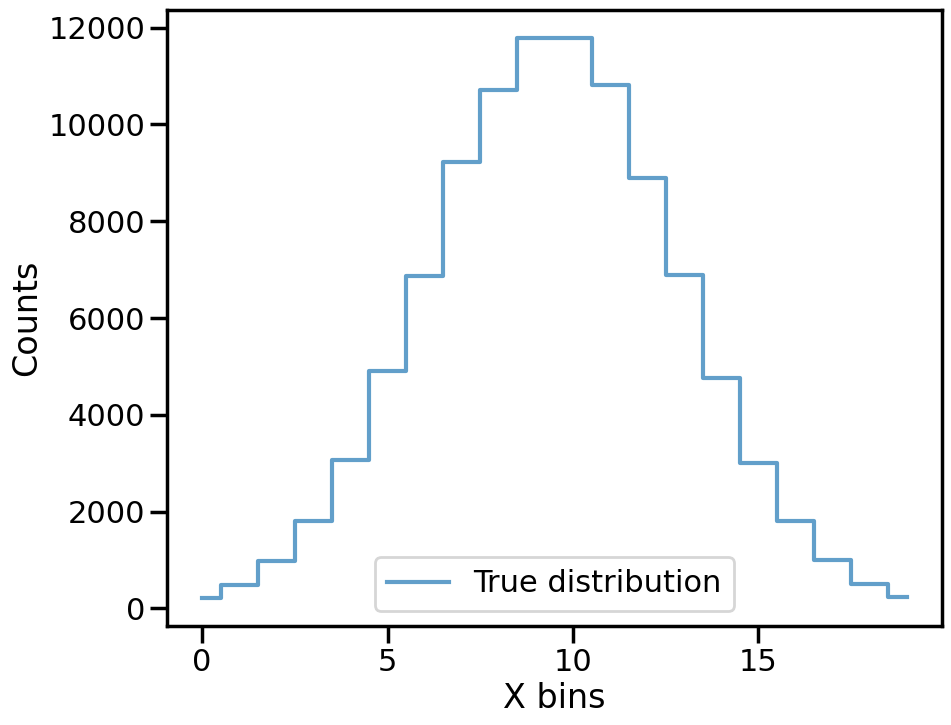

In [61]:
fig, ax = plt.subplots()
ax.step(np.arange(num_bins), data_true, where='mid', lw=3,
        alpha=0.7, label='True distribution')
ax.set(xlabel='X bins', ylabel='Counts')
ax.legend()
plt.show()

## Observed distribution

Generally speaking, measurement devices aren't perfect. This means that the measured value of $X$ isn't always exactly the same as the true value. That is, our measurement device has some inherit bias and resolution.

We'll model these detection imperfections by adding some random Gaussian noise to our true values of $X$ to get our observed (measured) values.

In [62]:
random_noise = np.random.normal(loc=0.3, scale=0.3, size=num_samples)
observed_samples = true_samples + random_noise

The observed values can be binned into a histogram. This array, `data_observed`, is the distribution we want to unfold.  

In [63]:
data_observed, _ = np.histogram(observed_samples, bins=bins)
data_observed

array([  111,   294,   618,  1112,  2027,  3230,  5002,  7120,  8852,
       10366, 11247, 11407, 10416,  8844,  6864,  4823,  3307,  2003,
        1169,   588])

We can see how the true and observed distribution of $X$ differ.

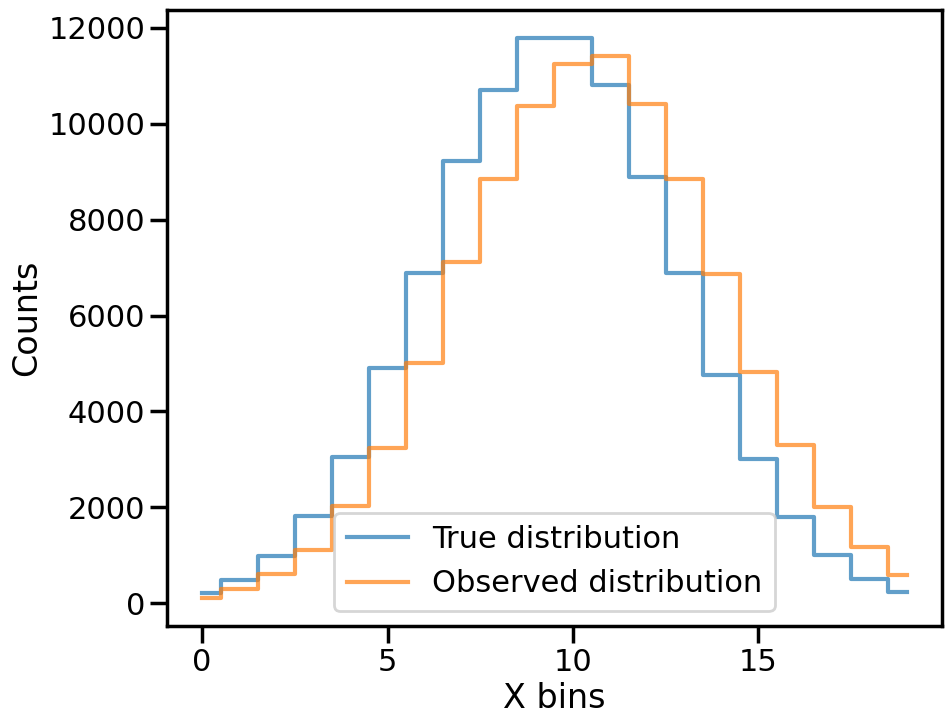

In [64]:
fig, ax = plt.subplots()
ax.step(np.arange(num_bins), data_true, where='mid', lw=3,
        alpha=0.7, label='True distribution')
ax.step(np.arange(num_bins), data_observed, where='mid', lw=3,
        alpha=0.7, label='Observed distribution')
ax.set(xlabel='X bins', ylabel='Counts')
ax.legend()
plt.show()

In addition to the observations themselves, the uncertainty of the observations is also needed to perform an unfolding. Here, we'll assume the errors are simply Poisson counting errors (i.e. $\mathrm{error_{i} = \sqrt{counts_{i}}}$).

In [65]:
data_observed_err = np.sqrt(data_observed)
data_observed_err

array([ 10.53565375,  17.1464282 ,  24.85960579,  33.346664  ,
        45.02221674,  56.83308895,  70.72481884,  84.38009244,
        94.08506789, 101.81355509, 106.0518741 , 106.80355799,
       102.05880658,  94.04254356,  82.84926071,  69.44782214,
        57.50652137,  44.754888  ,  34.19064199,  24.24871131])

## Detection Efficiencies

Not every sample from our true distribution will lead to a measured observation. The probability that a sample from our true distribution is observed is quantified via our detection efficiencies. For now, we'll assume uniform efficiencies of 1.

In [66]:
efficiencies = np.ones_like(data_observed, dtype=float)
efficiencies

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1.])

Likewise, let's assume an uncertainty on our efficiencies of 0.1.

In [67]:
efficiencies_err = np.full_like(efficiencies, 0.1, dtype=float)
efficiencies_err

array([0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1,
       0.1, 0.1, 0.1, 0.1, 0.1, 0.1, 0.1])

## Response matrix

The next step is to construct a response matrix that encapsulates our detector bias and resolution. This can be done by making a 2-dimensional histogram of the true vs. observed distributions.  

In [68]:
response_hist, _, _ = np.histogram2d(observed_samples, true_samples, bins=bins)

As with the uncertainties on our observed data, we'll assume Poisson counting errors for our response matrix.

In [69]:
response_hist_err = np.sqrt(response_hist)

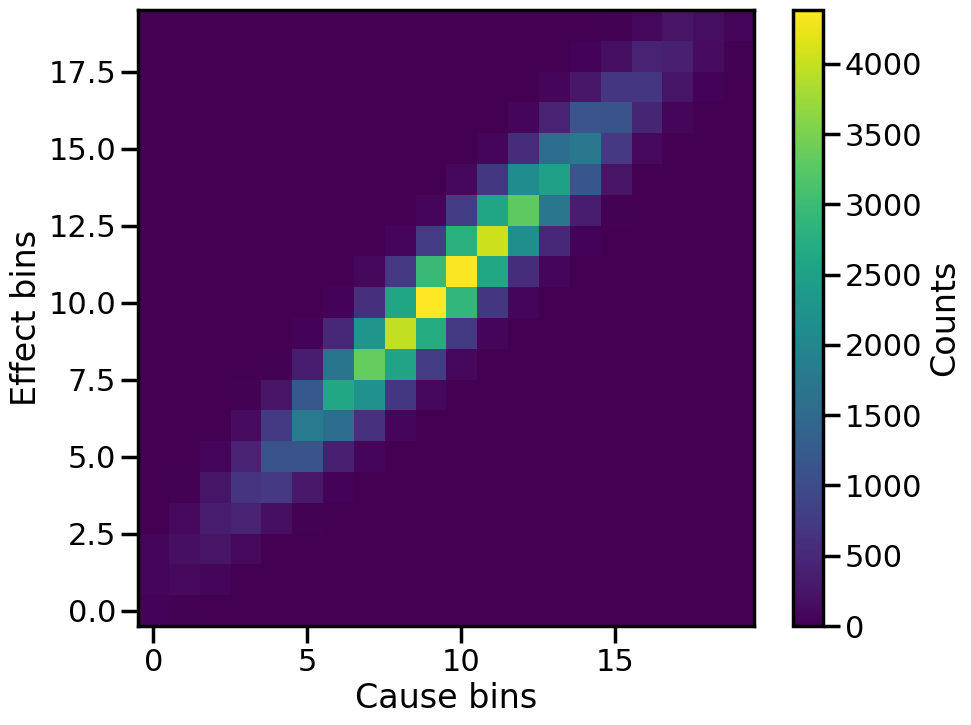

In [70]:
fig, ax = plt.subplots()
im = ax.imshow(response_hist, origin='lower')
cbar = plt.colorbar(im, label='Counts')
ax.set(xlabel='Cause bins', ylabel='Effect bins')
plt.show()

However, there's still one more step for the response matrix. What's needed for unfolding is not this 2-d counts histogram, but a matrix with the conditional probabilities $P(E_i|C_j)$. This matrix, called the normalized response matrix, can be obtained by normalizing our 2-d counts matrix. That is, scale each column of `response_hist` such that it adds to our detection efficiencies.

This normalization factor can be easily found via:

In [71]:
column_sums = response_hist.sum(axis=0)
normalization_factor = efficiencies / column_sums

In [72]:
response = response_hist * normalization_factor
response_err = response_hist_err * normalization_factor

As a check we can see that the columns of `response` add to our detection efficiencies.

In [73]:
response.sum(axis=0)

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       1., 1., 1.])

We can see how the structure of the 2-d response histogram differs from the normalized response matrix.

<>:3: SyntaxWarning: invalid escape sequence '\m'
<>:3: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_5982/3078604225.py:3: SyntaxWarning: invalid escape sequence '\m'
  cbar = plt.colorbar(im, label='$P(E_i|C_{\mu})$')


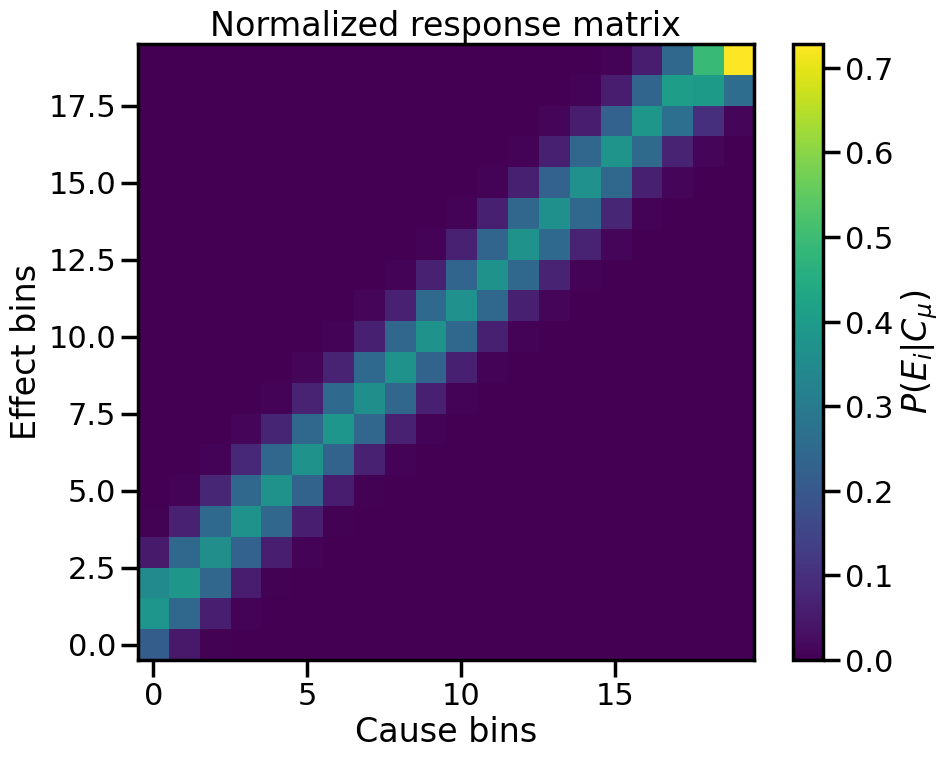

In [74]:
fig, ax = plt.subplots()
im = ax.imshow(response, origin='lower')
cbar = plt.colorbar(im, label='$P(E_i|C_{\mu})$')
ax.set(xlabel='Cause bins', ylabel='Effect bins',
       title='Normalized response matrix')
plt.show()

This difference in structure is because each column in the normalized response matrix is scaled by the number of samples in that column. So only the _relative_ structure of each column of the 2-d response histogram is present in the normalized response matrix.

<>:7: SyntaxWarning: invalid escape sequence '\m'
<>:7: SyntaxWarning: invalid escape sequence '\m'
/tmp/ipykernel_5982/2589000241.py:7: SyntaxWarning: invalid escape sequence '\m'
  cbar = plt.colorbar(im, label='$P(E_i|C_{\mu})$')


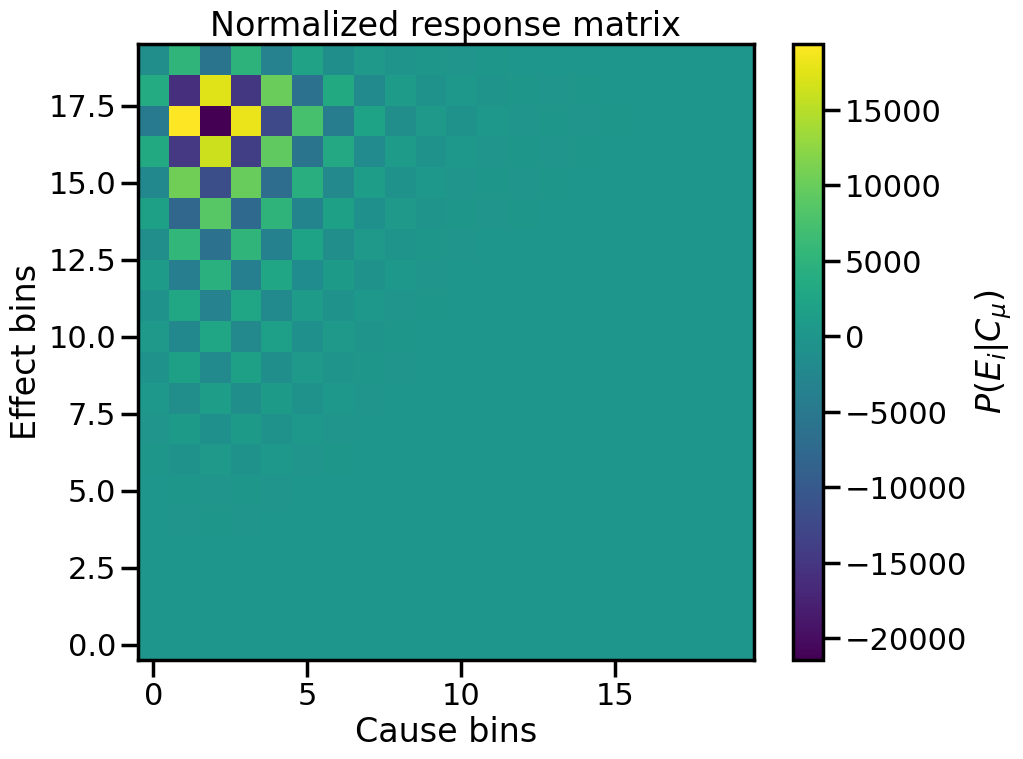

In [81]:
inv_res = np.linalg.inv(response)

#plot matrix

fig, ax = plt.subplots()
im = ax.imshow(inv_res, origin='lower')
cbar = plt.colorbar(im, label='$P(E_i|C_{\mu})$')
ax.set(xlabel='Cause bins', ylabel='Effect bins',
       title='Normalized response matrix')
plt.show()


## Iterative unfolding (Bayesian)

Now we have everything we need to perform our unfolding:

- Observed distribution to unfold (with uncertainties): `data_observed`, `data_observed_err`
- Detection efficiencies (with uncertainties): `efficiencies`, `efficiencies_err`
- Normalized response matrix (with uncertainties): `response`, `response_err`

These are all input parameters into the PyUnfold `iterative_unfold` function.

In [ ]:
unfolded_results = iterative_unfold(data=data_observed,
                                    data_err=data_observed_err,
                                    response=response,
                                    response_err=response_err,
                                    efficiencies=efficiencies,
                                    efficiencies_err=efficiencies_err,
                                    ts_stopping=0.01,
                                    max_iter=100,
                                    callbacks=[Logger()])

What's returned from `iterative_unfold` is a dictionary that contains:

- Unfolded distribution (`unfolded` key)
- Statistical uncertainties on the unfolded distribution (`stat_err` key)
- Systematic uncertainties on the unfolded distribution based on the response matrix uncertainties (`sys_err` key)
- Number of unfolding iterations to reach test statistic stopping condition (`num_iterations` key)
- Test statistic value for final iteration (`ts_iter` key)
- Test statistic stopping condition (`ts_stopping` key)
- Unfolding matrix (`unfolding_matrix` key)

In [ ]:
unfolded_results.keys()

In [ ]:
unfolded_results['unfolded']

In [ ]:
unfolded_results['sys_err']

Finally, we can see how the true, observed, and unfolded distributions compare to one another.

In [ ]:
fig, ax = plt.subplots()
ax.step(np.arange(num_bins), data_true, where='mid', lw=3,
        alpha=0.7, label='True distribution')
ax.step(np.arange(num_bins), data_observed, where='mid', lw=3,
        alpha=0.7, label='Observed distribution')
ax.errorbar(np.arange(num_bins), unfolded_results['unfolded'],
            yerr=unfolded_results['sys_err'],
            alpha=0.7,
            elinewidth=3,
            capsize=4,
            ls='None', marker='.', ms=10,
            label='Unfolded distribution')

ax.set(xlabel='X bins', ylabel='Counts')
plt.legend()
plt.show()

In [ ]:
#inverting matrix response
